# vibrational.generation.hc

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.generation.hc')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "vibrational.generation.hc",
  "status": "recorded_results",
  "source_sha256": {
    "vib2mol_xinyu_random64_20261116.json": "9f452a28aef3ff5af315cdbe1340c1844f7e3af139896490fba2d268fc970cc8"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "target": "CC(C)OCC1=NC(C2CCC2)=CS1",
  "raw_beams": {
    "length": 10,
    "first_values": [
      "CC(C)OCC1=NC(C2CCC2)=CS1",
      "CC(OCC1=NC(=CS1)C1CCC1)C",
      "CC(OCC1=NC(C2CCC2)=CS1)C",
      "CC(OCC1SC=C(N=1)C1CCC1)C",
      "CC(OCC1SC=C(C2CCC2)N=1)C",
      "C1CCC1C1=CSC(=N1)COC(C)C",
      "C1CCC1C1=CSC(COC(C)C)=N1",
      "C1(CCC1)C1=CSC(=N1)COC(C)C"
    ]
  },
  "unique_candidates": [
    "CC(C)OCC1=NC(C2CCC2)=CS1"
  ],
  "reranked": [
    "CC(C)OCC1=NC(C2CCC2)=CS1"
  ],
  "positive_probabilities": [
    0.9998494386672974
  ],
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.005309805274009705,
        0.005845691077411175,
        0.006656948011368513,
        0.007852676324546337,
        0.009617962874472141,
        0.012248368002474308,
        0.016140293329954147,
        0.02150154486298561
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.004348924849182367,
        0.0044013503938913345,


## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | exact_canonical_top1 | 0.75 |
| recorded sample | recorded model | exact_canonical_top5 | 0.890625 |
| recorded sample | recorded model | valid_smiles_fraction | 0.959375 |
| recorded sample | recorded model | examples | 64 |
| recorded sample | ITM reranked | exact_canonical_top1 | 0.6875 |
| recorded sample | ITM reranked | exact_canonical_top5 | 0.890625 |


{
  "top1_matches_reference_this_example": true
}


## 预测／参考对照图

已遵循作者生成协议，但同一 64 样本上 ITM 重排使 top-1 从 0.75 降到 0.6875；应先复查这项退化，再考虑重排器适配。

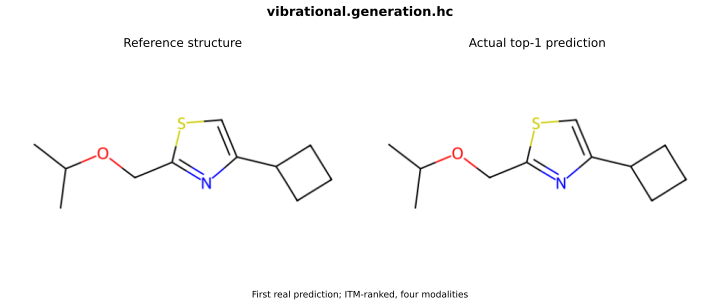

In [4]:
figure = render('vibrational.generation.hc', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/vibrational-generation-hc.md) · [Quick Start](../quickstart.md)
